# Project NYPD Enforcement Gap
##### Team Members: Haeji Ahn, Amy Lin, Amanda Song

## 1. Introduction

The New York Police Department (NYPD) is the largest municipal police department in the United States, with a huge operating budget that is greater than the combined budgets of several other agencies in New York City. Our project aims to study enforcement patterns, particularly when a stop, question, and frisk (SQF) action is undertaken by the police, and identify what kinds of stops lead to physical escalation by the police. We aim to answer the question: To what extent do demographic characteristics (e.g, race, age, and sex) and situational factors (e.g., location, why the stop was initiated, and the suspected crime) predict the use of physical force during a police encounter?

By identifying which factors are correlated with an increased risk of use of physical force, we can increase transparency regarding the NYPD's enforcement patterns, exposing systemic institutional biases that may exist. 

## 2. Data

Our dataset is an Excel file from the NYPD's SQF database, containing detailed information on all documented pedestrian stops made by NYPD officers, based on the NYPD UF-250 form that they fill out post-stop. We specifically focused on the most recent dataset from 2025, which has 26,422 records. 

We used the following features:
1. "SUSPECT_RACE_DESCRIPTION": Description of individual's race
2. "SUSPECT_REPORTED_AGE": Reported age of individual
3. "SUSPECT_SEX": Sex of individual
4. "STOP_WAS_INITIATED": Whether a stop was initiated based on C/W on scene, from a radio run, or self-initiated
5. "SUSPECTED_CRIME_DESCRIPTION": Crime that the individual was suspected to have committed
6. "STOP_LOCATION_PATROL_BORO_NAME": One of 8 police patrol boroughs where the stop occurred (e.g., Manhattan North, Manhattan South)

Our output feature is whether or not a police officer used physical force, which we extracted by combining the following features: "PHYSICAL_FORCE_CEW_FLAG", "PHYSICAL_FORCE_DRAW_POINT_FIREARM_FLAG", "PHYSICAL_FORCE_HANDCUFF_SUSPECT_FLAG", "PHYSICAL_FORCE_OC_SPRAY_USED_FLAG", "PHYSICAL_FORCE_OTHER_FLAG", "PHYSICAL_FORCE_RESTRAINT_USED_FLAG", and "PHYSICAL_FORCE_WEAPON_IMPACT_FLAG".

We conducted comprehensive data cleaning and preparation to ensure that our dataset was prepared for model training and analysis. Key pre-processing steps included:

1. Filtering for our selected features. 
2. Replacing values that had the string "(null)" with actual NaN values.
3. Standardizing string data by converting to lowercase, removing whitespace, and replacing forward slashes with underscores.
4. Converting age values to numeric format while coercing any invalid entries.
5. Dropping rows with NaN values in race, age, sex, and location features, as these records were incomplete.
6. Dropping records where suspects' ages were below 12, as these were likely data entry errors.
7. Aggregating ages into broader categories (<18, 18–24, 25–44, 45–54, >=55), utilizing classifications referenced from an NYC Mayor's Office of Criminal Justice report on youth arrests and recidivism.
8. Recoding missing values in physical force columns to 0 and "Y" values to 1, as these missing entries indicated that no physical force was applied.

To further prepare the data for modeling, we converted categorical features into numerical format using one-hot encoding. To avoid multicollinearity, we manually dropped one baseline category for each feature (white, female, based on radio run, pbsi, >=55, and criminal trespass). Finally, we aggregated the multiple physical force indicator columns into a single binary target feature representing whether any form of physical force was used by the NYPD during the interaction.

One limitation of our dataset is that it is slightly imbalanced, with approximately 80% negative labels and 20% positive labels. We addressed this imbalance by implementing model-specific strategies to adjust class weights. Knowing that accuracy would be a poor metric due to the skew of the data, and because we wanted to ensure we did not miss any incidents where physical force was used, we prioritized recall as our primary evaluation metric. Additionally, the dataset did not have a corresponding data dictionary, which required us to infer the meanings of certain abbreviations through further desktop research. For example, under the "STOP_WAS_INITIATED" feature, there was a value "Based on C/W on Scene", which we interpreted as whether there was a "complainant or witness" on scene. Although we attempted to obtain official data definitions from the NYPD, we unfortunately did not receive a response from the dataset owners.

## 3. Models and Results

We trained and evaluated our dataset using three model classes:
1. Linear model: Logistic regression
2. Non-linear model: Decision trees and random forests
3. Neural network model

Prior to training, we split our dataset into training and testing sets using scikit-learn's *train_test_split* to ensure that we had unbiased data to evaluate our model's performance post-training and tuning. We also set the same seed, 123, across all our models to ensure reproducibility of our analysis and results.

Based on our research question on predicting the use of force by the NYPD, we found it especially important to minimize false negatives, as failing to identify cases where physical force is used may understate instances where certain demographic groups are disproportionately affected. We selected the optimal hyperparmater combinations for our models to maximize recall. In contrast, while accuracy is an evaluation metric that is commonly used in machine learning, this was not our focus due to the moderate class imbalance in our dataset. 

Of our models, the neural network was the best-performing model, with a recall score of 0.7666 on the test set, while our linear model (logistic regression) was the worst-performing model, with a recall score of 0.6755 on the test set. This aligns with our expectations, as whether or not a police officer chooses escalate to use of physical force is often the result of multiple confounding factors. While the linear model assumes that the features act independently, the non-linear neural network model captures how the different variables interact to create structural outcomes.

### 3.1. Linear Model: Logistic Regression

#### 3.1.1. Model Set-up and Hyperparameter Tuning

We decided to use logistic regression to train our linear model. Logistic regression enabled us to identify variables that are more strongly associated with the probability of physical force and predict a binary outcome based on the given demographic and situational features, especially since our data is not perfectly linearly separable. 

We initialized our model using scikit-learn's *LogisticRegression* class, where we set *solver="liblinear"* to allow for both L1 and L2 regularization, and set *class_weight="balanced"* to assign higher weights to the minority class during model training given the imbalance of our dataset. To prepare for cross-validation during the training process, we defined how our training set should be split by using scikitlearn's *KFold*, implementing 5-fold cross-validation in subsequent steps.

Key hyperparameters that we wanted to tune were mainly related to regularization:
1. **Penalty type**: L1 or L2
2. **C**: Inverse of penalty strength (1.0, 0.1, 0.01, 0.001, 0.0001)  

Because our model contains a sizable number of features, we aimed to effectively control its complexity and prevent overfitting, which made tuning the above hyperparameters important. We defined a parameter grid that included the hyperparameters we wanted to tune and specified multiple evaluation metrics (accuracy, precision, recall, F1). Using the cross-validation split defined earlier, we passed these into scikit-learn's *GridSearchCV* and fit the search on our training data to find the optimal hyperparameter combination. As mentioned, we prioritized recall, so we set *refit="recall"* such that the best hyperparameter combination returned would correspond to the one that yielded the highest recall score. The optimal model returned had a C = 0.01 with L1 regularization, achieving a recall score of 0.6615.

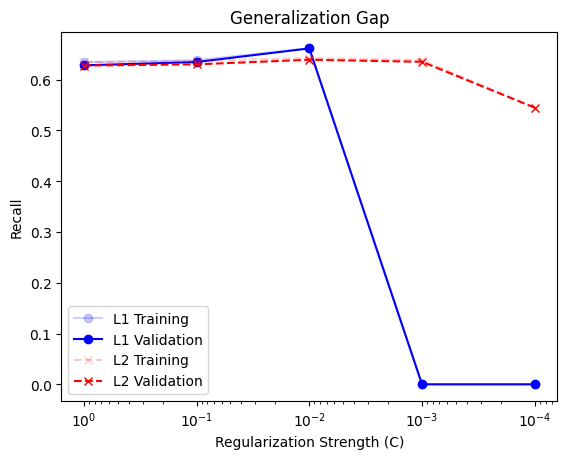

#### 3.1.2. Estimated Weights and Bias

Using the tuned hyperparameters from the optimal model, we obtained the estimated coefficients and bias term for our classifier. Because L1 regularization was applied, many feature weights were set to zero, leaving only 11 features with non-zero weights that were identified as having the highest importance to our model's predictions of the use of force by the NYPD. Among these, the features with the largest positive weights (indicating a higher likelihood of force being used) were whether the stop occurred in Manhattan South (0.4941) and whether the suspect was male (0.1566). These two features increase the odds of use of force by 63.9% and 17.0% respectively. On the other hand, the features with the largest negative weights (indicating a lower likelihood of force being used) were whether the stop was self-initiated (-0.5444) and whether the stop was in the Bronx (-0.3083). These two features decrease the odds of use of force by 42.0% and 26.5% respectively.

We had previously expected racial features to play a larger role in predicting outcomes. However, only one racial feature -- whether the suspect was identified as Black -- had a non-zero weight, and its weight was rather small albeit positive (0.0362), representing a 3.7% increase in odds of use of force. One possible explanation is that some racial effects may have been absorbed into correlated geographic or situational features, like patrol boroughs, due to multicollinearity between features. 

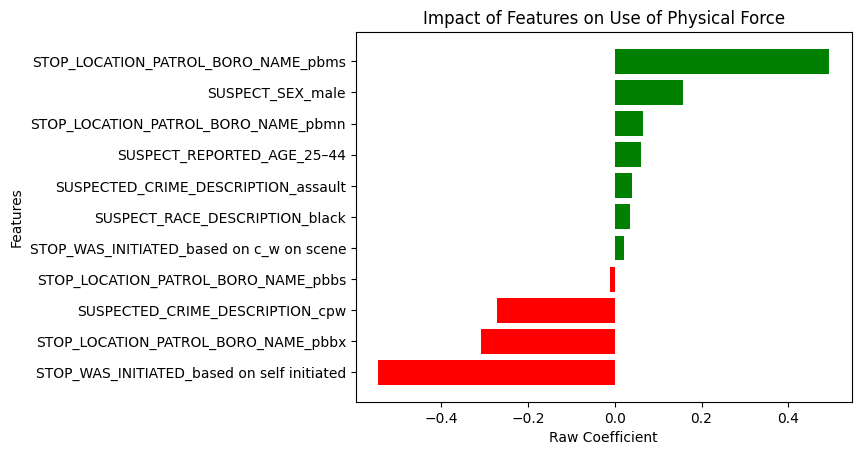

#### 3.1.3. Testing and Evaluation

We applied the tuned hyperparameters from the optimal model to our testing set by calling *predict(X_test)* on the fitted grid_search model. Using scikit-learn's *classification_report* to compare our predictions against actual labels in the testing set, we evaluated key evaluation metrics, including recall, precision, F1 score, and accuracy. The model achieved a recall score of 0.6755 on our test set, which was slightly higher than the recall score obtained during validation. The F1 score, precision, and accuracy were 0.4144, 0.2989, and 0.5878 respectively.

Overall, while our model was able to correctly identify a meaningful number of positives in our dataset, which was in line with our goal to minimize false negatives, its performance definitely had room for improvement. The relatively low scores across all metrics returned from the testing set suggested that a linear model may not have been sufficiently flexible to capture more complex patterns and relationships in our dataset. 

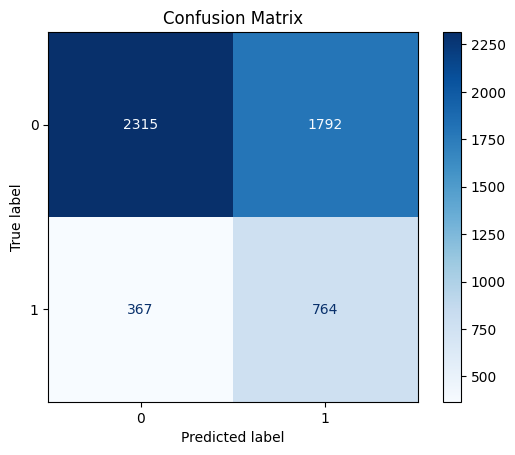

### 3.2. Non-linear Model: Decision Trees and Random Forest

#### 3.2.1. Decision Tree

##### 3.2.1.1. Model Set-up and Hyperparameter Tuning

Among the non-linear models, we picked decision tree-based architectures. Given the size (26,000 observations) and high dimensionality of our dataset, decision trees are exceptionally well-suited to model complex, non-linear relationships among our features without assuming a rigid linear structure. They are also less sensitive to outliers and inherently capable of identifying the most significant features during training. 

To train our non-linear model, we first implemented a single *DecisionTreeClassifier* and set *class_weight="balanced"* to assign higher weights to the minority class during model training given the imbalance of our dataset. To prepare for cross-validation during the training process, we defined how our training set should be split by using scikit-learn's *KFold*, implementing 5-fold cross-validation in subsequent steps.

Key hyperparameters that we wanted to tune to control tree complexity and prevent overfitting:
1. **max_depth**: Maximum depth of the tree (3, 5, 7, 10, 20, None)
2. **min_samples_split**: Minimum samples required to split an internal node (2, 5, 10)
3. **min_samples_leaf**: Minimum samples required at a leaf node (1, 2, 4)
4. **criterion**: The function to measure the quality of a split (gini, entropy)

We defined a parameter grid that included these hyperparameters and specified multiple evaluation metrics (accuracy, precision, recall, F1). Using the cross-validation split defined earlier, we passed these into scikit-learn's *GridSearchCV* and fit the search on our training data to find the optimal hyperparameter combination. Our primary goal is to minimize false negatives, we prioritized recall and set *refit="recall"* so we can get the best hyperparameter combination returned would correspond to the one that yielded the highest recal score. The optimal model returned possessed a restricted max_depth of 5 and utilized the gini criterion, achieving a cross-validation recall score of approximately 0.70.

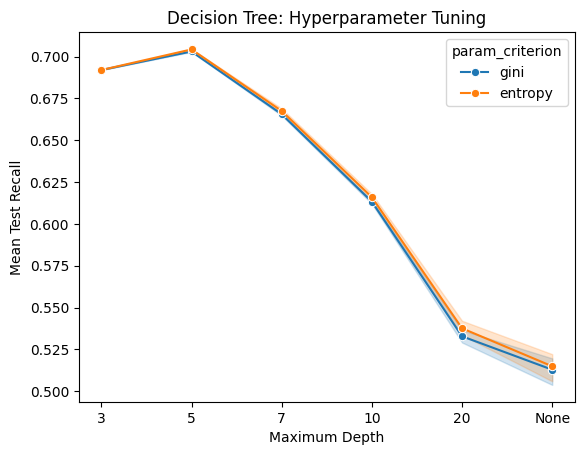

##### 3.2.1.2. Feature Importance Interpretation

Unlike the logistic regression model which yields directional coefficients, decision tree compute feature importance based on the mean decrease in impurity (Gini importance). This metric quantifies how efficiently a feature isolates the target variable without assuming a linear relationship or dictating a strict positive or negative direction.

From the decision tree, a single feature emerged with overwhelming dominance feature -- whether the stop was self-initiated by the officer -- accounting for approximately 50% of the entire model's predictive weight. This strongly echoes the large negative coefficient found in our linear model, implying that proactive policing contexts are structurally distinct from dispatched calls regarding force escalation. Geographic markers, such as patrol boroughs (Manhattan South and specific Bronx sectors), constituted the secondary tier of importance. Conversely, individual demographic and racial features possessed negligible direct importance, suggesting that any racial disparate impacts in policing force are structurally embedded within geography and situational contexts rather than acting as isolated and linear predictors.

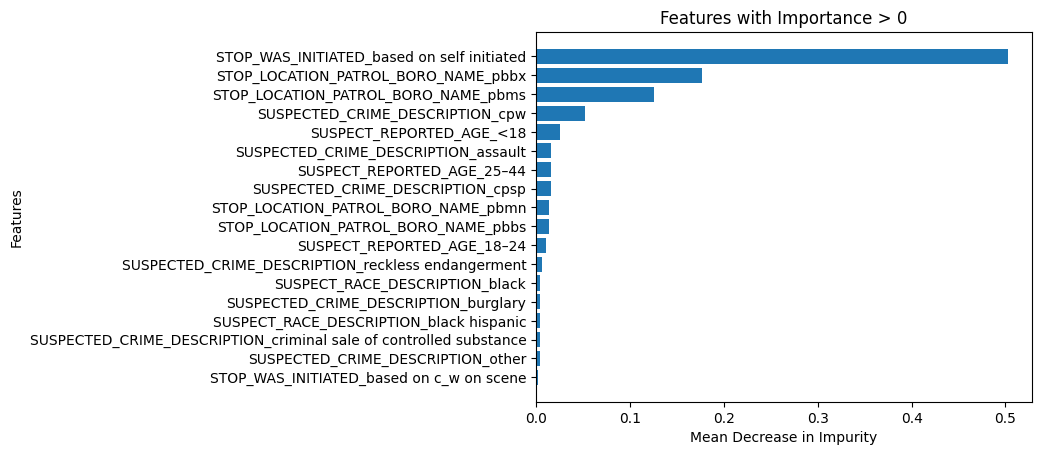

##### 3.2.1.3. Testing and Evaluation

We applied the tuned hyperparameters from the optimal model to our testing set by calling *predict(X_test)* on the fitted grid_search model. Using scikit-learn's *classification_report* to compare our predictions against actual labels in the testing set, we evaluated key evaluation metrics, including recall, precision, F1 score, and accuracy. The model achieved a recall score of 0.69 on our test set, which was slightly lower than the recall score obtained during validation. The F1 score, precision, and accuracy were 0.41, 0.30, and 0.58 respectively.

Overall, our model was able to correctly identify a meaningful number of positives in our dataset which align with our goal to minimize false negatives. its performance definitely had room for improvement. The relatively low precision (0.30) returned from the testing set suggested that while a single tree is flexible enough to capture minority class instances aggressively, its rigid, block-like decision boundaries struggle to establish a robust prediction criteria without triggering a high volume of false alarms.

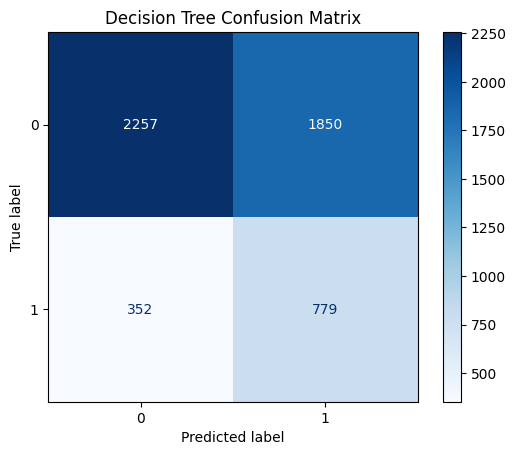

#### 3.2.2. Random Forest


##### 3.2.2.1. Set-up and Hyperparameter Tuning

To address the inherent instability and high variance associated with one single decision tree, we plan to enhance the model by implementing the random forest algorithm. By aggregating predictions across multiple independent trees via bootstrap sampling and random feature selection, the random forest ensemble controls model complexity, effectively prevents overfitting, and significantly improves overall predictive performance.

We extended our analysis by initializing a *RandomForestClassifier*. We maintained the identical 5-fold cross-validation scheme and incorporated *class_weight="balanced_subsample"* to calibrate the bootstrap samples against the class imbalance of our dataset.

The tuning grid was expanded to systematically evaluate combinations across a multi-dimensional parameter space:

1. **n_estimators**: Number of trees in the forest (50, 100, 150)
2. **max_depth**: Maximum depth of the trees (3, 5, 7, 10, 20, None)
3. **min_samples_split**: Minimum samples required to split an internal node (2, 5, 10)
4. **min_samples_leaf**: Minimum samples required at a leaf node (1, 2, 4)
5. **criterion**: The function to measure the quality of a split (gini, entropy)

Using parallelized *GridSearchCV*, the optimal ensemble structure was selected based on the cross-validation performance. As with the previous models, we set *refit="recall"* to ensure the selected parameters aligned with our strategic evaluation priorities.

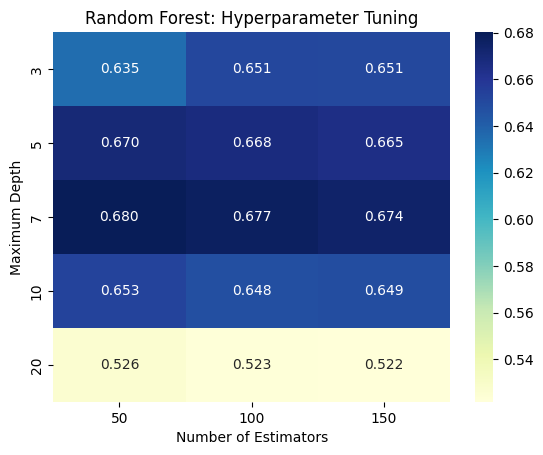

##### 3.2.2.2. Feature Importance Interpretation

The feature importance profile of the Random Forest provided a more robust and smoothed representation compared to the single tree. While STOP_WAS_INITIATED_based on self initiated remained a critical factor, its importance score was less localized, as the random feature selection mechanism (max_features) forced individual trees to explore alternative predictive signals.

Geographic indicators and specific precinct attributes maintained stable and distributed importance scores across the forest. This behavior confirms that non-linear models are highly reliant on spatial and situational context to predict the use of force, dampening the reliance on a single 'shortcut' feature and providing a more generalized understanding of the policing data.

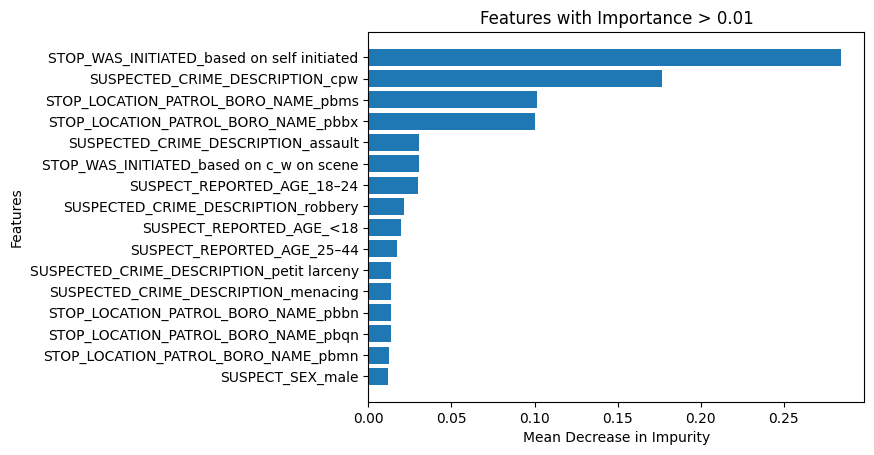

##### 3.2.2.3. Testing and Evaluation

We applied the tuned hyperparameters from the optimal model to our testing set by calling *predict(X_test)* on the fitted grid_search model. Using scikit-learn's *classification_report* to compare our predictions against actual labels in the testing set, we evaluated key evaluation metrics, including recall, precision, F1 score, and accuracy. The model achieved a recall score of 0.70 on our test set, which successfully surpassed the recall score obtained from the standalone Decision Tree. Furthermore, the F1 score and precision also experienced marginal improvements, returning at 0.42 and 0.30 respectively, while maintaining a stable accuracy of 0.58.

Overall, our model demonstrated an exceptional performance profile that broke the typical trade-off barrier between recall and precision. This improvement returned from the testing set suggested that the ensemble's democratic majority-voting mechanism successfully smoothed out the erratic and high-variance predictions of individual trees. By acting as a robust cooperative filter, the Random Forest proved to be a more flexible, stable, and generalizable framework for capturing complex policing relationships without over-indexing on localized sample variances.


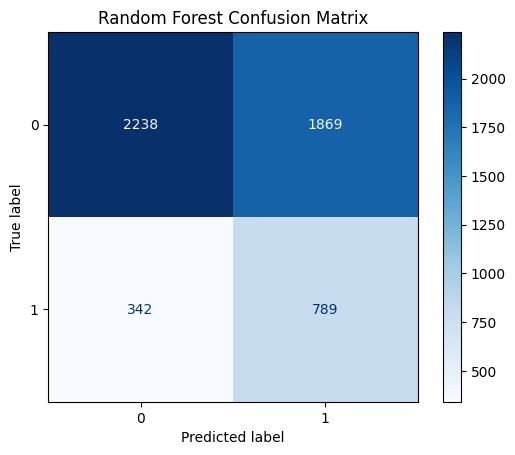

#### 3.2.3. Model Performance Comparison

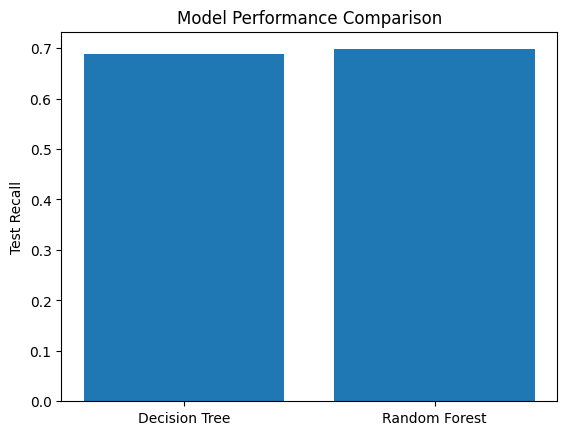

### 3.3. Neural Network Model

#### 3.3.1. Model Set-up and Hyperparameter Tuning

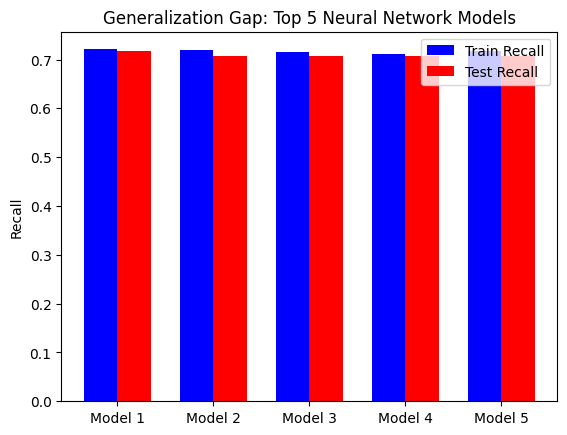

#### 3.3.2. xxx

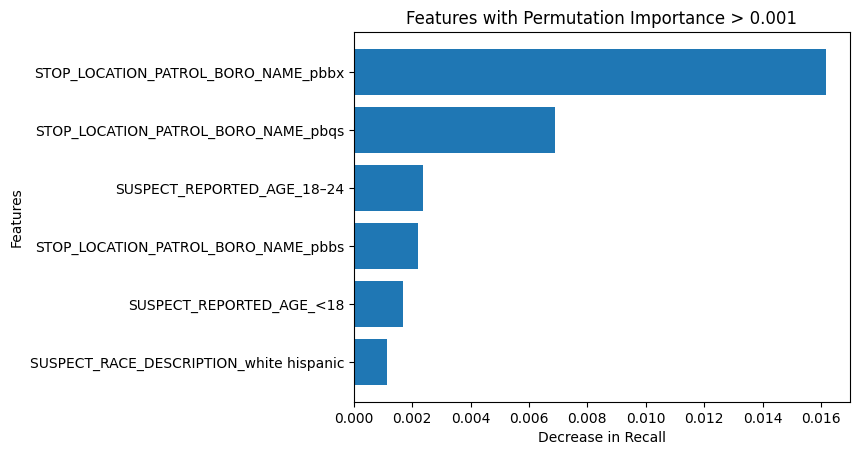

#### 3.3.3. Testing Evaluation

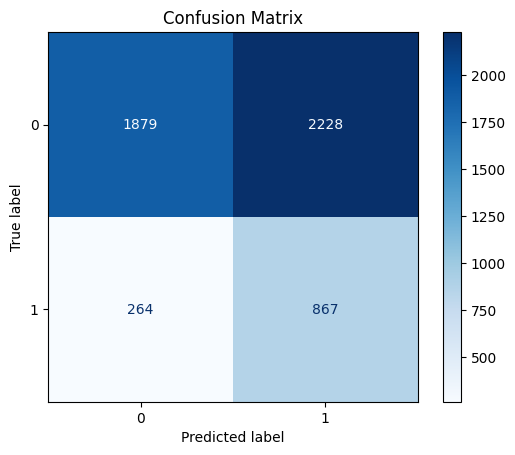

## 4. Learnings and Challenges

Did anything unexpected happen? What parts of the project were surprisingly difficult? 

Over the course of the project, we were able to apply the models and tools learnt in class to a real-world dataset, which helped us understand how these methods can be used to examine policy issues. We also built upon our learning by adopting more advanced packages and functions specialized in certain parts of the machine learning pipeline, such as cross-validation specific tools.

We faced several challenges along the way that translated into meaningful and concrete learning experiences. One such challenge that arose was during the hyperparameter tuning process. In class assignments, we were often given specific hyperparameters to tune, but in this project, we realized that there were many hyperparameter combinations that could be explored. As such, we had to strategically select hyperparameter combinations to prioritize, balancing robustness and contribution to model performance against computational cost and time.

Furthermore, we encountered some issues in feature selection and multicollinearity. 
Cut deterministic features
Tried to reduce multicollinearity across features -- selecting suitable granularity for our geographic features, using regularization to highlight features that are more important to our analysis

## 5. Conclusion

[What did you learn about your research question? What did you learn about machine learning through the tasks?  How would you continue this research if you wanted to further investigate? If you had more time and infinite resources, how would you continue your project?]

Overall, our project set out to examine the extent to which demographic characteristics and situational factors predict the use of force by the NYPD during a SQF encounter. While the different models produced slightly different results, they generally had consistent patterns, which enabled us to have a better understanding of the relative predictive importance of the various factors.

Although we initially anticipated that individual demographic characteristics would be the primary predictors of physical force, we found that situational factors had much larger predictive importance. Situational factors such as how a stop was initiated and the location of a stop were often weighted high in predictive power. As these factors often outranked demographics, our findings seemed to suggest that the use of force may be less about individual instances of racism and more about how the broader system is designed.

Moving forward, we hope to continue working on this project by exploring more advanced approaches to mitigate multicollinearity, which would likely improve model accuracy and interpretability. We could also expand our project scope by including data from multiple years to observe if there were broader temporal trends that could not be captured through our single-year dataset, thereby enhancing the robustness of our analysis.